# Import libraries

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import mglearn 
from IPython.display import Image
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score  
from sklearn import svm, metrics
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, silhouette_score, mean_squared_error, r2_score 
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV
from cycler import cycler
from sklearn.decomposition import PCA
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
from sklearn.metrics import f1_score, precision_score, recall_score
import warnings
warnings.filterwarnings('ignore')  

# Characterisation of the dataset

In [5]:
# Import the file for races
df= pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')

In [7]:
#Verification of the first 5 rows
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [9]:
#Verification of the last 5 rows
df.tail()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
2106,Female,20.976842,1.710730,131.408528,yes,yes,3.0,3.0,Sometimes,no,1.728139,no,1.676269,0.906247,Sometimes,Public_Transportation,Obesity_Type_III
2107,Female,21.982942,1.748584,133.742943,yes,yes,3.0,3.0,Sometimes,no,2.005130,no,1.341390,0.599270,Sometimes,Public_Transportation,Obesity_Type_III
2108,Female,22.524036,1.752206,133.689352,yes,yes,3.0,3.0,Sometimes,no,2.054193,no,1.414209,0.646288,Sometimes,Public_Transportation,Obesity_Type_III
2109,Female,24.361936,1.739450,133.346641,yes,yes,3.0,3.0,Sometimes,no,2.852339,no,1.139107,0.586035,Sometimes,Public_Transportation,Obesity_Type_III
2110,Female,23.664709,1.738836,133.472641,yes,yes,3.0,3.0,Sometimes,no,2.863513,no,1.026452,0.714137,Sometimes,Public_Transportation,Obesity_Type_III


In [11]:
#Quantity of features and variables
df.shape

(2111, 17)

# Application of Data preparation/evaluation methods and EDA

In [14]:
#Find missing values per feature
df.isnull().sum()

Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC                              0
NCP                               0
CAEC                              0
SMOKE                             0
CH2O                              0
SCC                               0
FAF                               0
TUE                               0
CALC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64

In [16]:
#Important data
df.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


<Axes: xlabel='Age', ylabel='Count'>

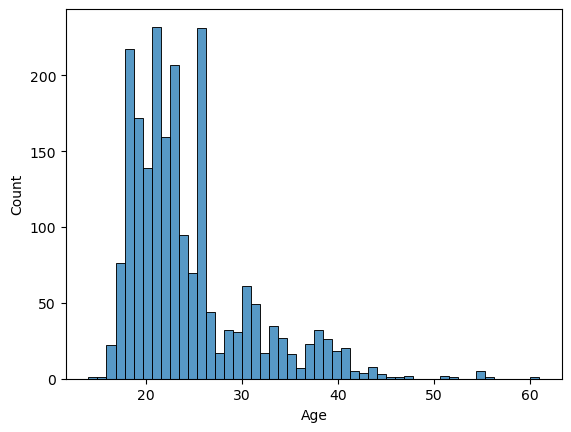

In [18]:
sns.histplot(data=df, x="Age")

<Axes: xlabel='Height', ylabel='Count'>

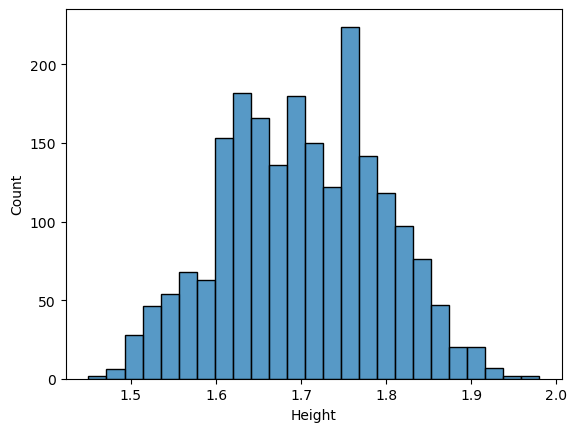

In [20]:
sns.histplot(data=df, x="Height")

<Axes: xlabel='Weight', ylabel='Count'>

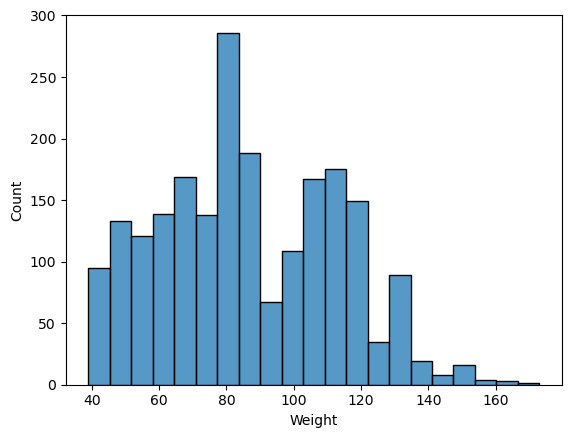

In [22]:
sns.histplot(data=df, x="Weight")

In [24]:
# Indicate the unique values in the numeric and categorical columns
num_col = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

# Convert numeric columns
for col in num_col:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# No resign
df[num_col].info()

print("Updated data types for numeric columns:")
print(df[num_col].dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Age     2111 non-null   float64
 1   Height  2111 non-null   float64
 2   Weight  2111 non-null   float64
 3   FCVC    2111 non-null   float64
 4   NCP     2111 non-null   float64
 5   CH2O    2111 non-null   float64
 6   FAF     2111 non-null   float64
 7   TUE     2111 non-null   float64
dtypes: float64(8)
memory usage: 132.1 KB
Updated data types for numeric columns:
Age       float64
Height    float64
Weight    float64
FCVC      float64
NCP       float64
CH2O      float64
FAF       float64
TUE       float64
dtype: object


In [26]:
# Indicate the unique values in the columns
columns = ['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP','CAEC','SMOKE','CH2O','SCC',
           'FAF', 'TUE', 'CALC', 'MTRANS','NObeyesdad']

for i in columns:
    print(f'{i} unique values:' , df[i].unique())

Gender unique values: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Age unique values: [21.       23.       27.       ... 22.524036 24.361936 23.664709]
Height unique values: [1.62     1.52     1.8      ... 1.752206 1.73945  1.738836]
Weight unique values: [ 64.        56.        77.       ... 133.689352 133.346641 133.472641]
family_history_with_overweight unique values: <StringArray>
['yes', 'no']
Length: 2, dtype: str
FAVC unique values: <StringArray>
['no', 'yes']
Length: 2, dtype: str
FCVC unique values: [2.       3.       1.       2.450218 2.880161 2.00876  2.596579 2.591439
 2.392665 1.123939 2.027574 2.658112 2.88626  2.714447 2.750715 1.4925
 2.205439 2.059138 2.310423 2.823179 2.052932 2.596364 2.767731 2.815157
 2.737762 2.568063 2.524428 2.971574 1.0816   1.270448 1.344854 2.959658
 2.725282 2.844607 2.44004  2.432302 2.592247 2.449267 2.929889 2.015258
 1.031149 1.592183 1.21498  1.522001 2.703436 2.362918 2.14084  2.5596
 2.336044 1.813234 2.724285 2.71897  1.133

In [28]:
# Clean target just in case there are missing values
df['NObeyesdad'] = df['NObeyesdad'].astype(str).str.strip()

# LabelEncoder
le = LabelEncoder()
df["NObeyesdad"] = le.fit_transform(df["NObeyesdad"])

# Target with 7 levels
target_map = {'Insufficient_Weight': 0, 'Normal_Weight': 1, 'Overweight_Level_I': 2, 'Overweight_Level_II': 3, 'Obesity_Type_I': 4,
              'Obesity_Type_II': 5, 'Obesity_Type_III': 6}

df['NObeyesdad'] = df['NObeyesdad'].replace(target_map)

# Binary map
binary_map = {'no': 0, 'yes': 1}
df['family_history_with_overweight'] = df['family_history_with_overweight'].replace(binary_map)
df['FAVC'] = df['FAVC'].replace(binary_map)
df['SMOKE'] = df['SMOKE'].replace(binary_map)
df['SCC'] = df['SCC'].replace(binary_map)
df['Gender'] = df['Gender'].replace({'Female': 0, 'Male': 1})

#Categorical map
ordinal_map = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3 }
df['CAEC'] = df['CAEC'].replace(ordinal_map)
df['CALC'] = df['CALC'].replace(ordinal_map)

#Onehot Encoding nominal
df = pd.get_dummies(df, columns=['MTRANS'], drop_first=True)

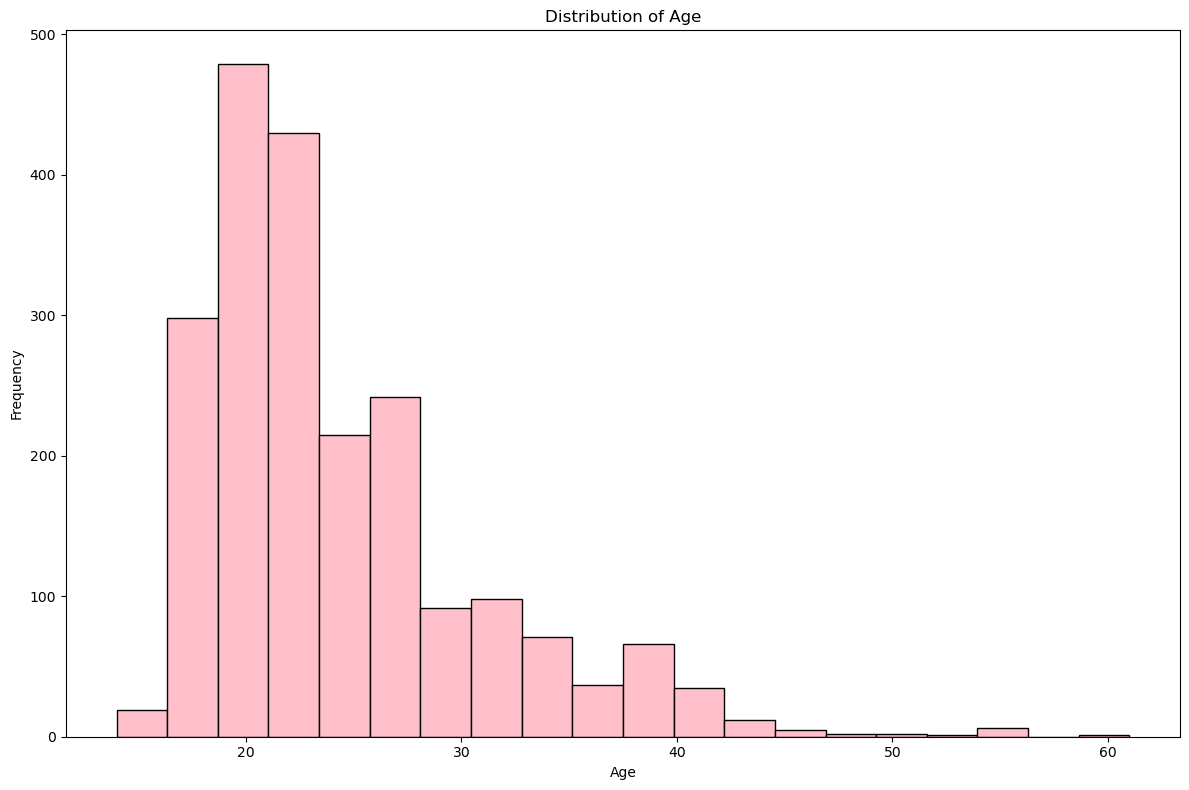

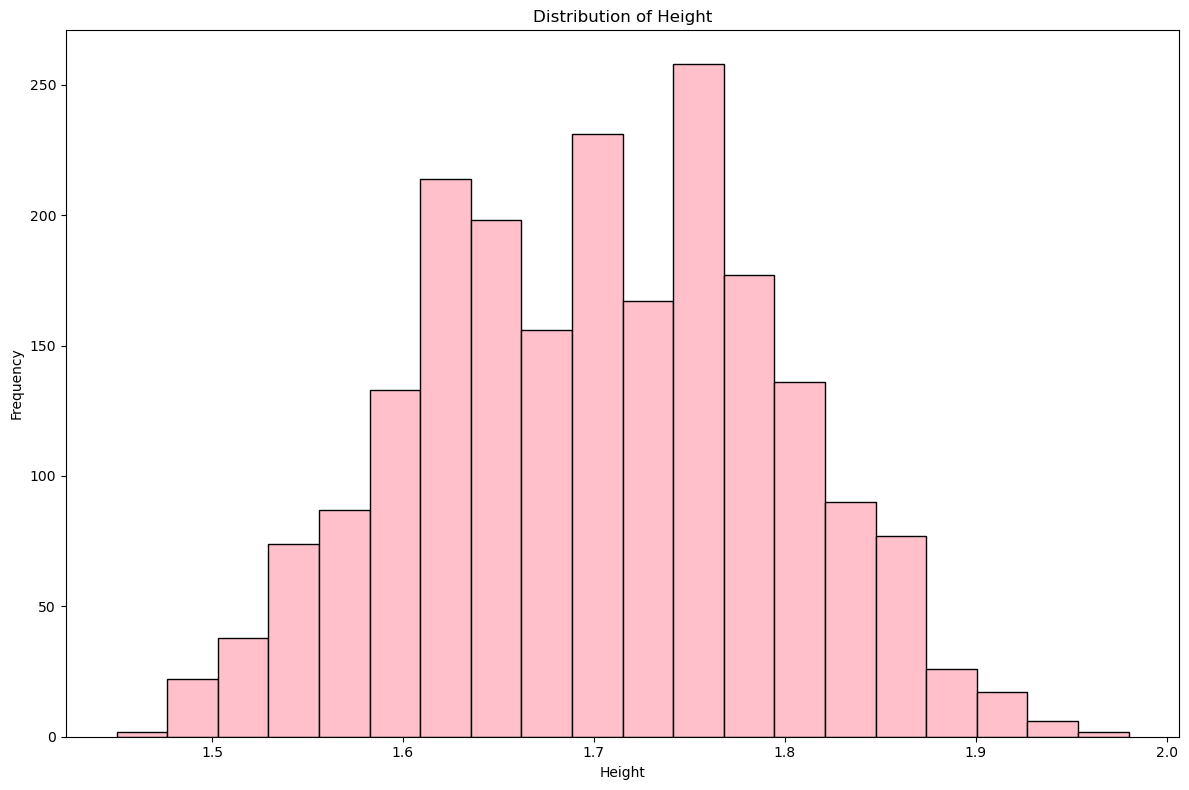

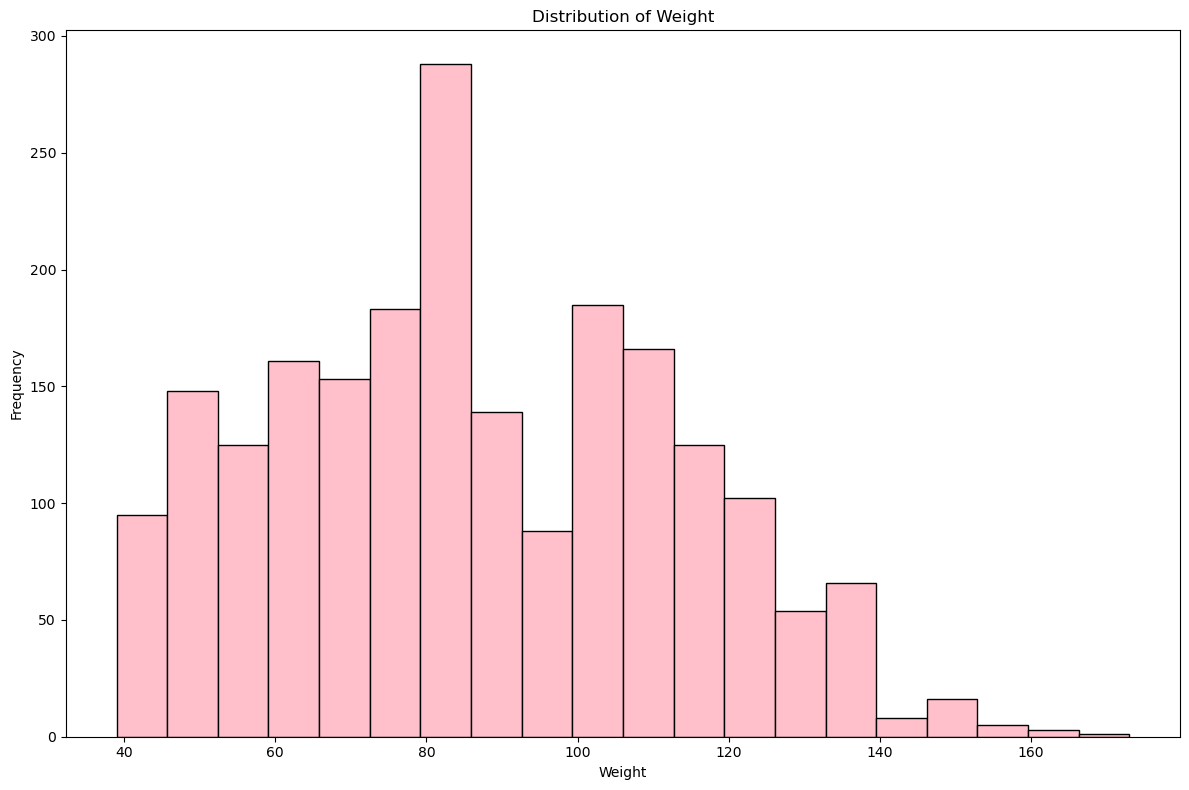

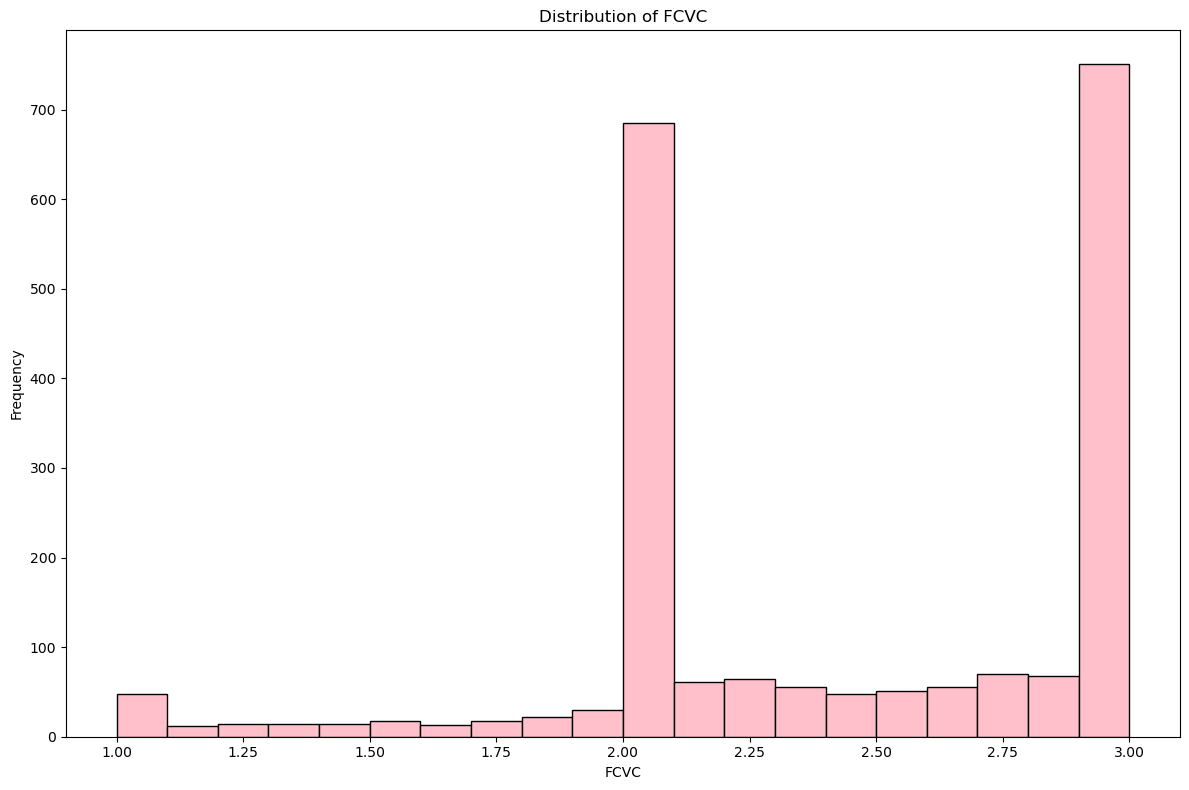

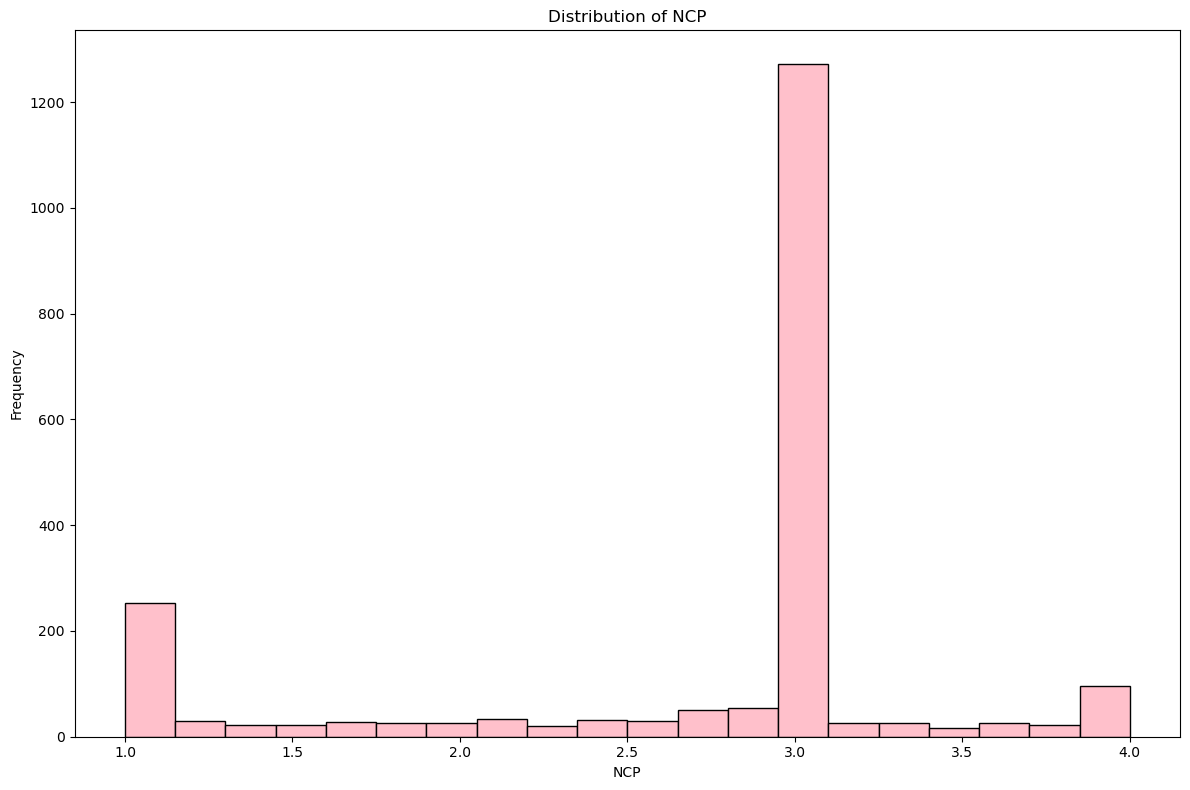

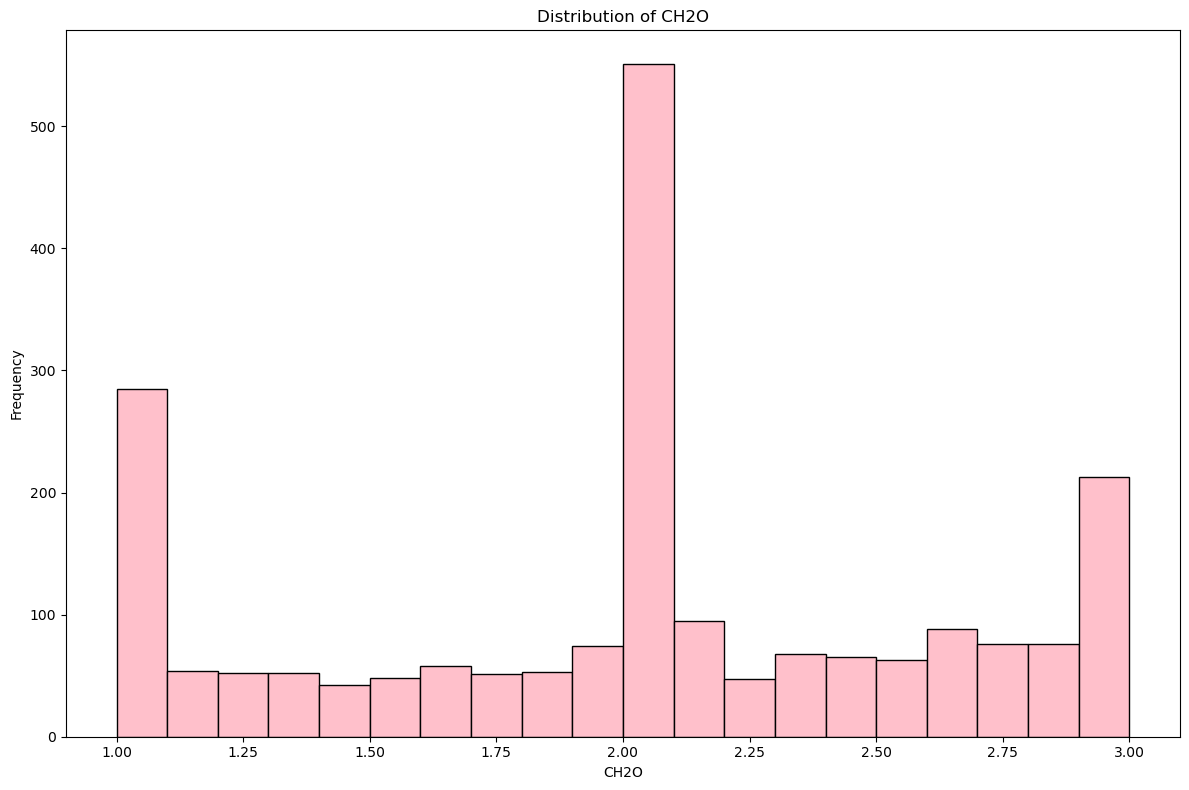

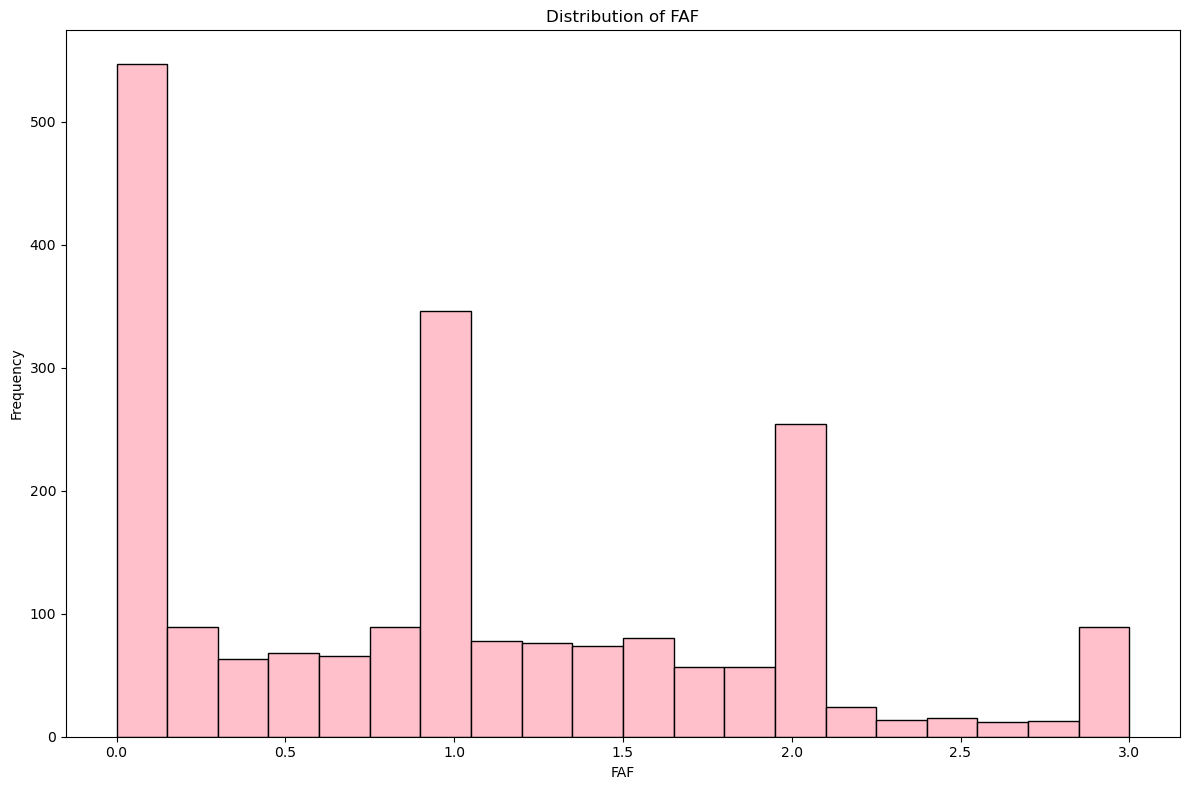

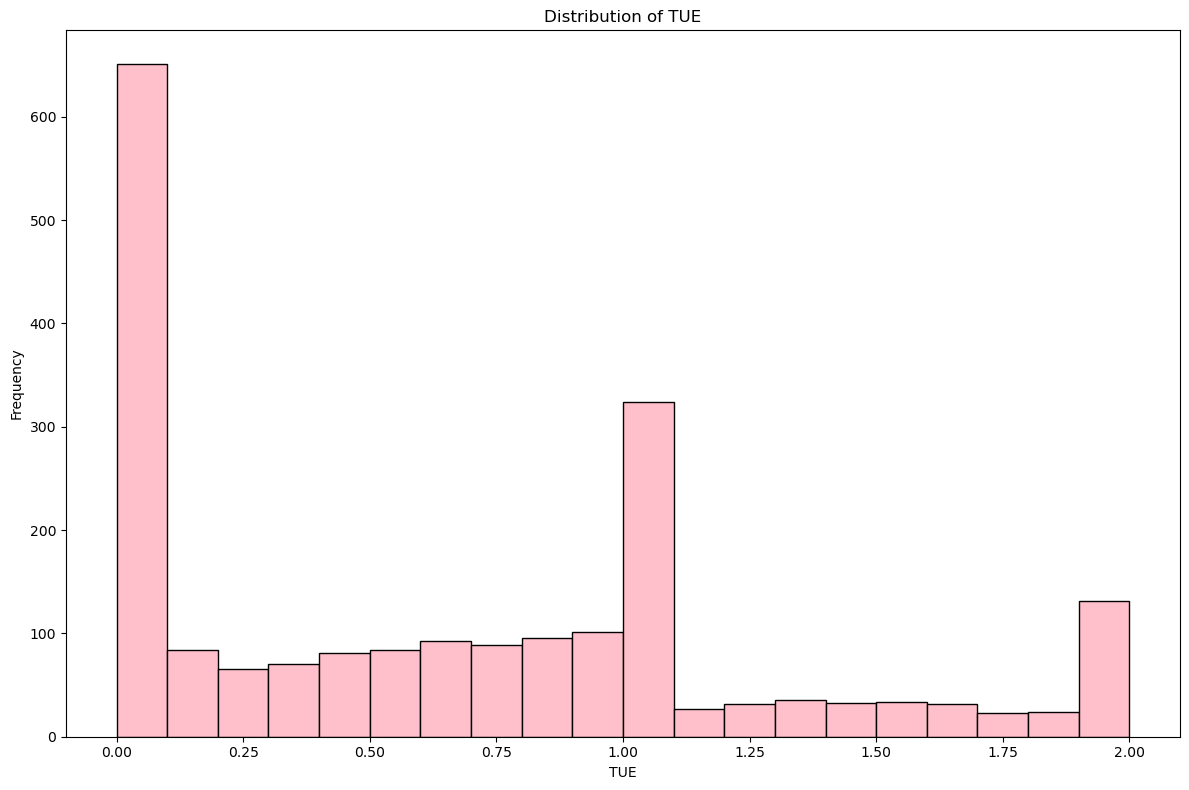

In [30]:
#Continuous columns
cont_col = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

df[cont_col] = df[cont_col].apply(pd.to_numeric, errors="coerce")

for i in cont_col:
    fig, ax = plt.subplots(figsize=(12, 8))
    
# Histogram graphic
    ax.hist(df[i].dropna(), bins=20, color='pink', edgecolor='black')
    ax.set_title(f'Distribution of {i}')
    ax.set_xlabel(i)
    ax.set_ylabel('Frequency')
    plt.tight_layout()
    plt.show()

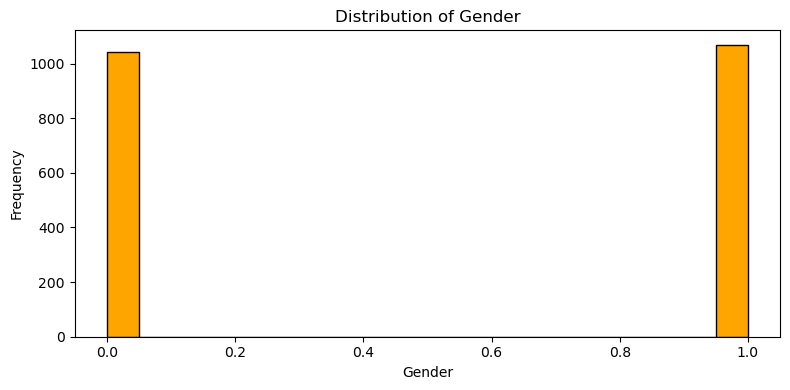

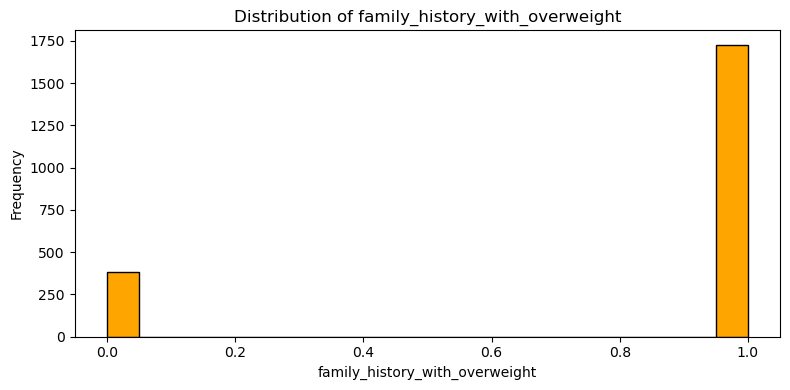

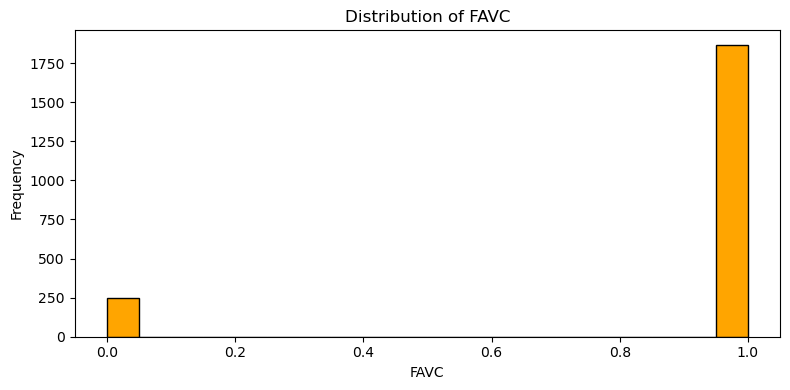

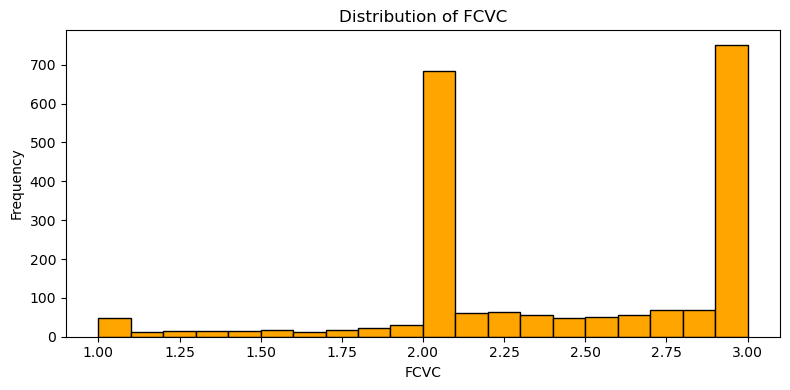

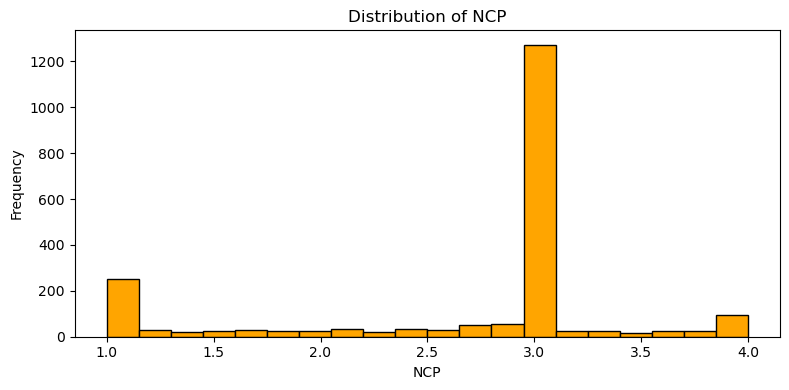

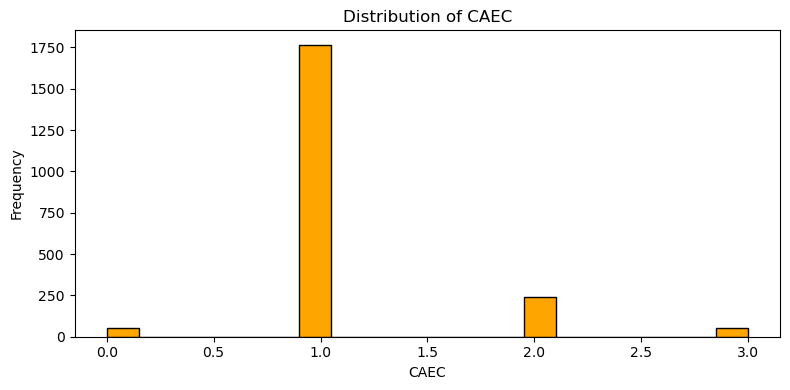

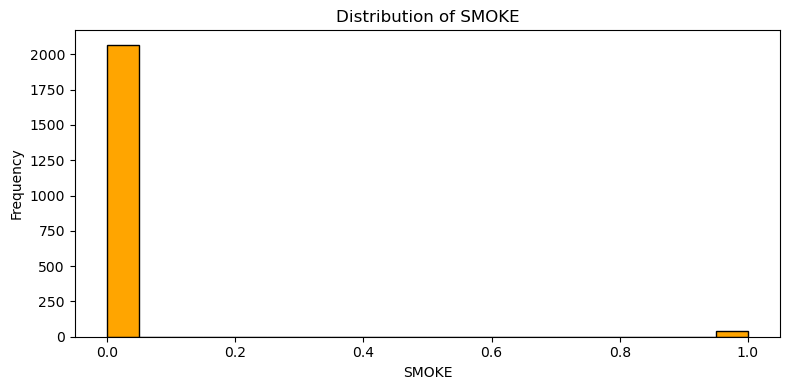

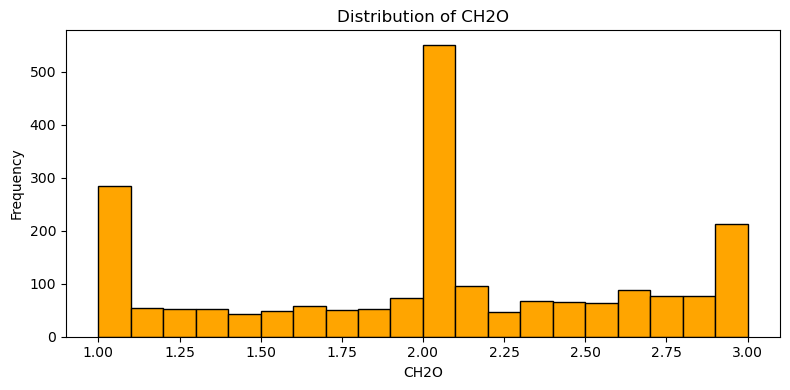

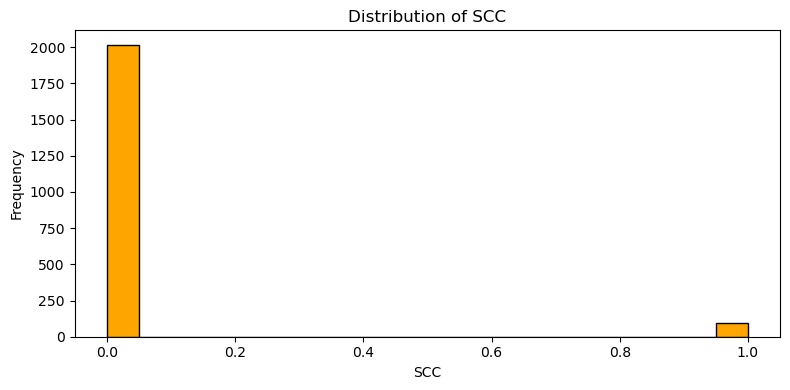

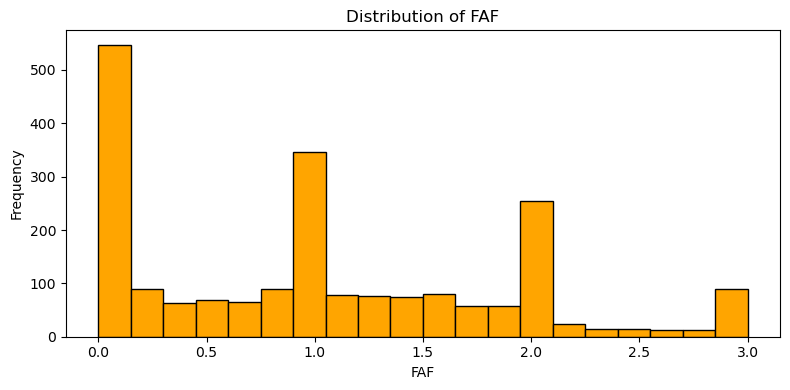

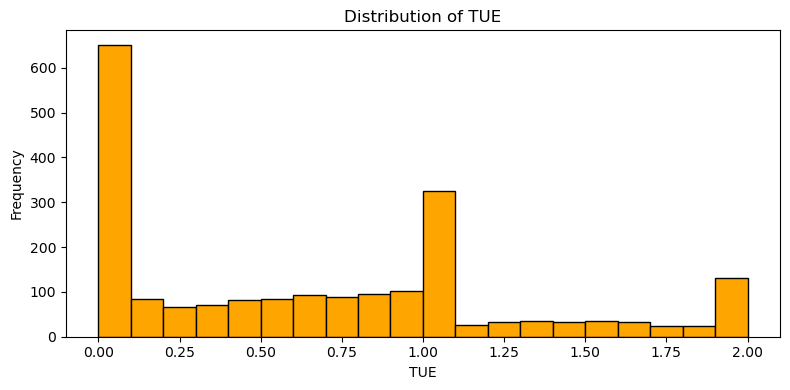

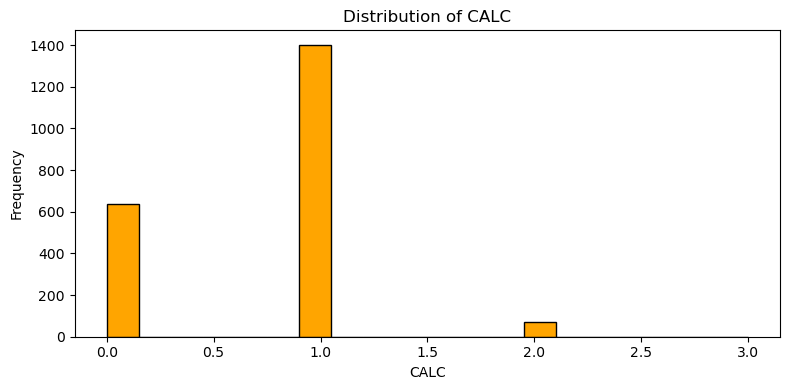

TypeError: numpy boolean subtract, the `-` operator, is not supported, use the bitwise_xor, the `^` operator, or the logical_xor function instead.

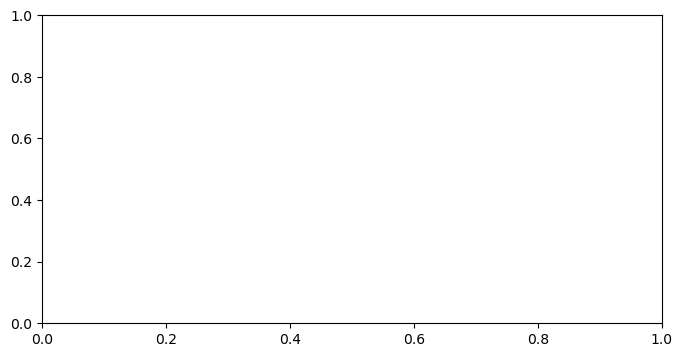

In [129]:
#REVISAR AHORA TODOS LOS PUTOS GRAFICOS ME DAN IGUALES HAY QUE REVISAR

#Integer columns
integ_col = ['Gender', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS']

#Interg columns + MTRANS
col_to_plot = []
for i in integ_col:
    if i in df.columns:
        col_to_plot.append(i)

# Columns created for dummies MTRANS
mtrans_col = [c for c in df.columns if c.startswith("MTRANS")]
col_to_plot.extend(mtrans_col)
    
# Histogram
for i in col_to_plot:
    fig,ax = plt.subplots(figsize=(8,4))
    ax.hist(df[i].dropna(), bins=20, color='orange', edgecolor='black')
    ax.set_title(f'Distribution of {i}')
    ax.set_xlabel(i)
    ax.set_ylabel('Frequency')
    plt.tight_layout()
    plt.show()

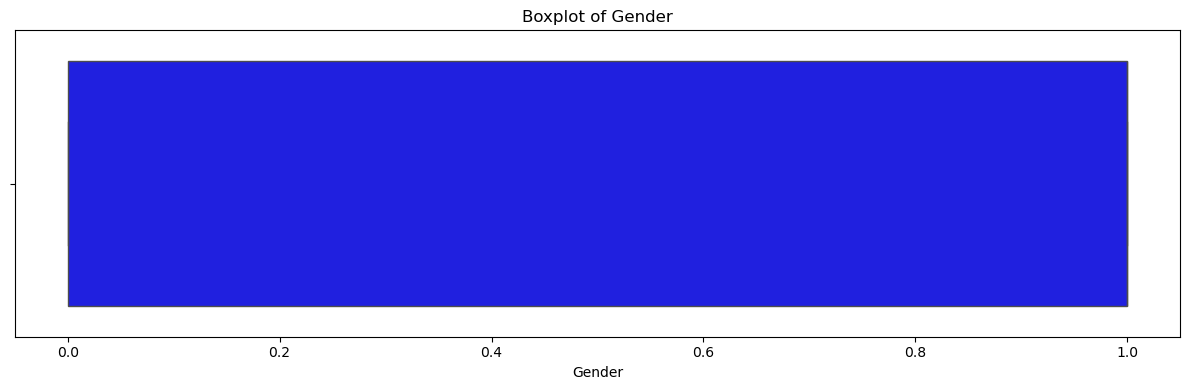

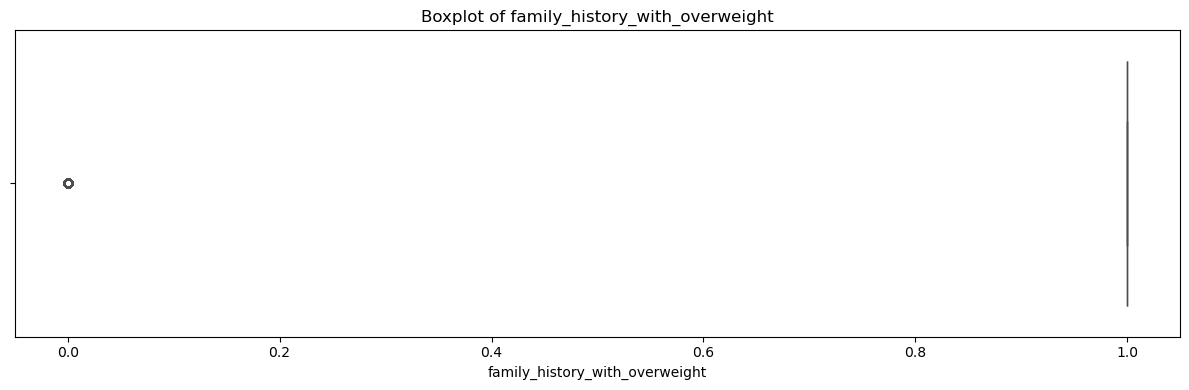

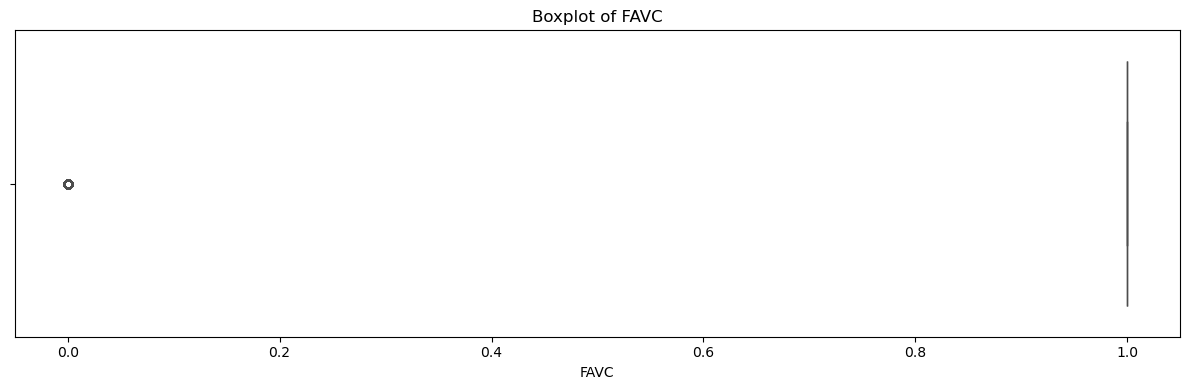

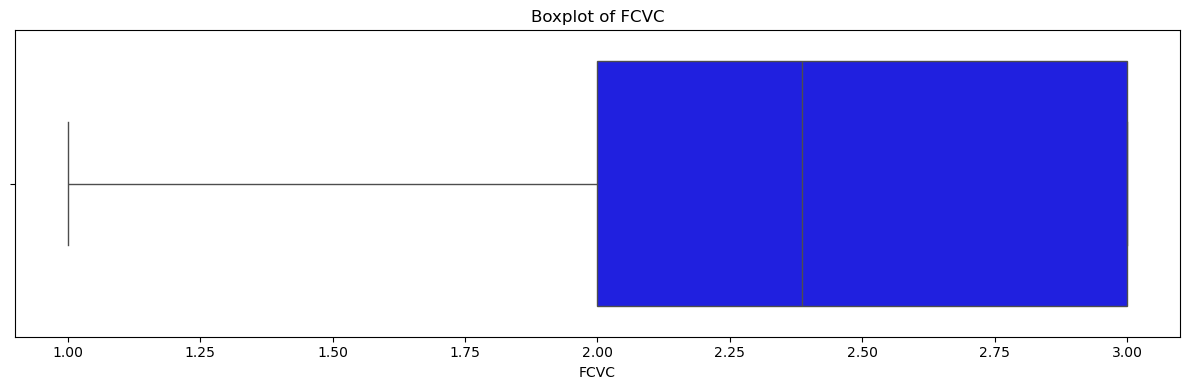

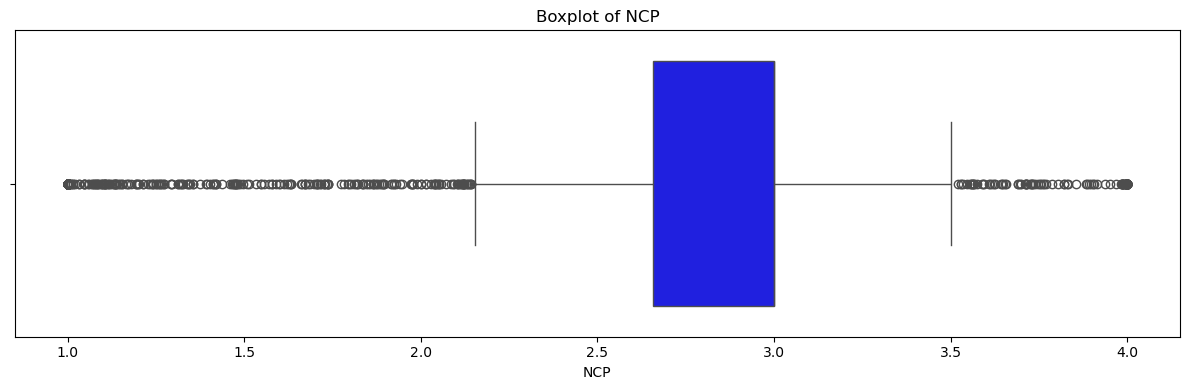

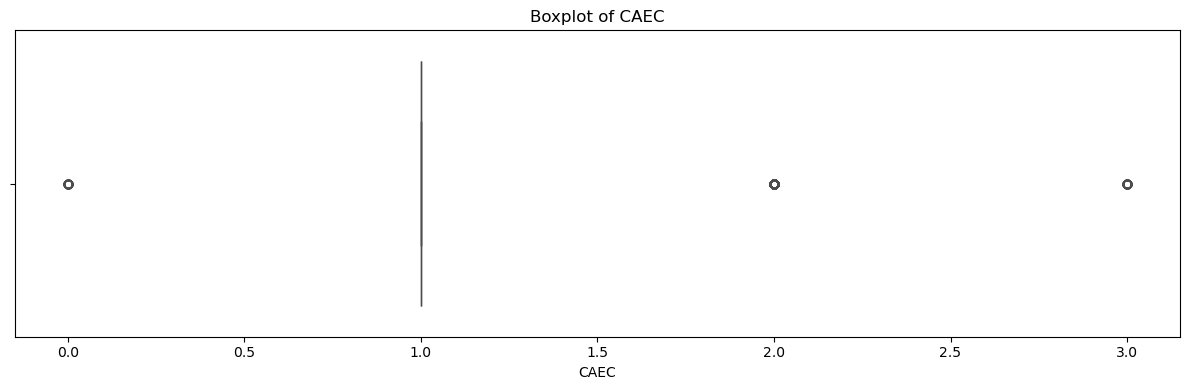

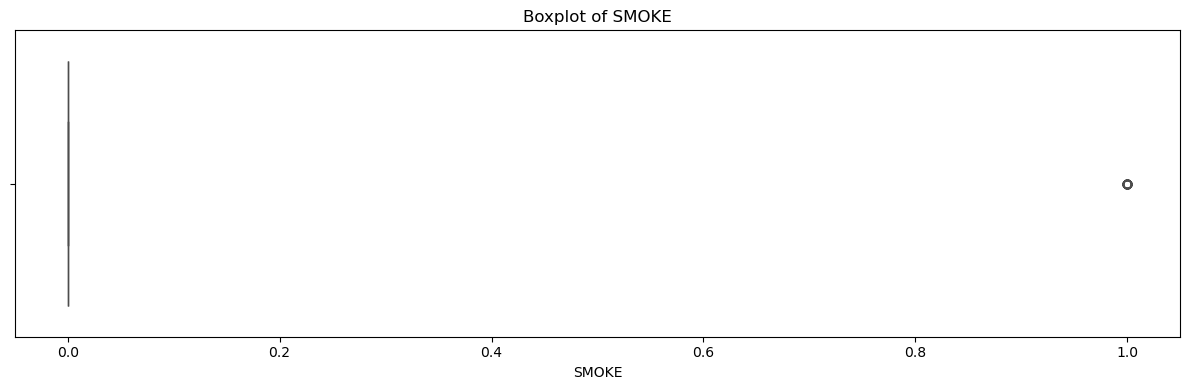

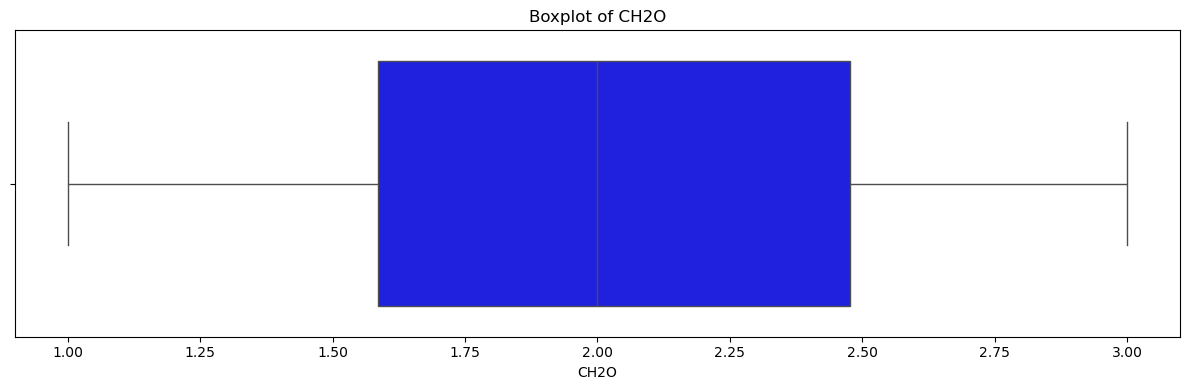

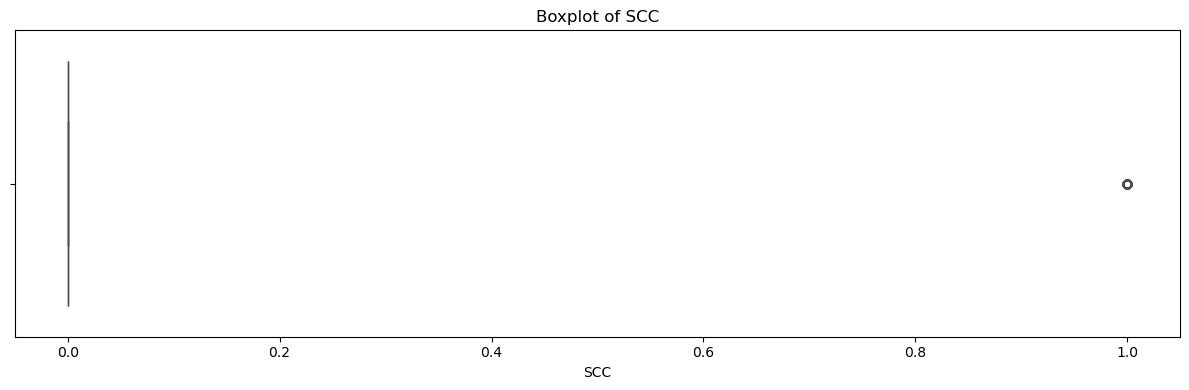

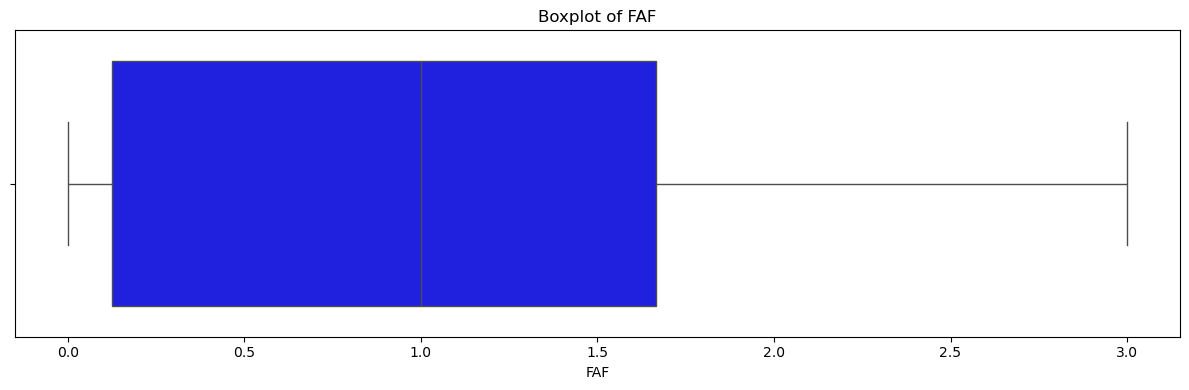

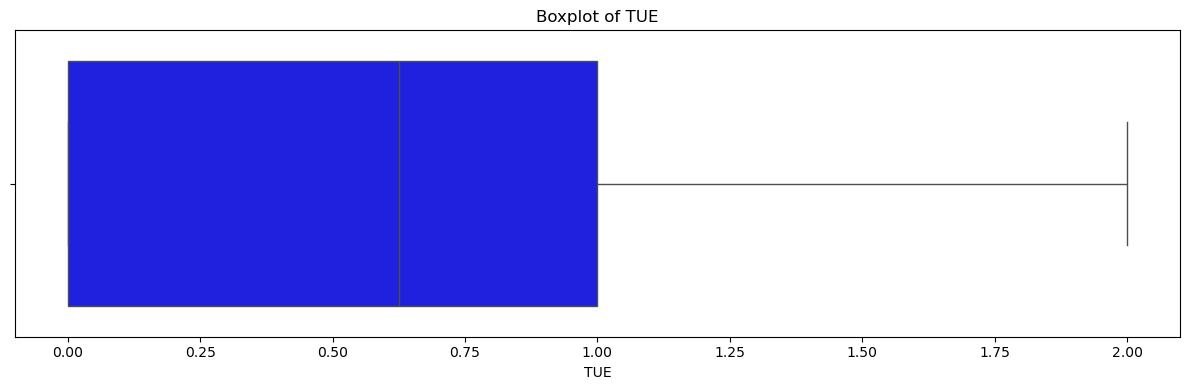

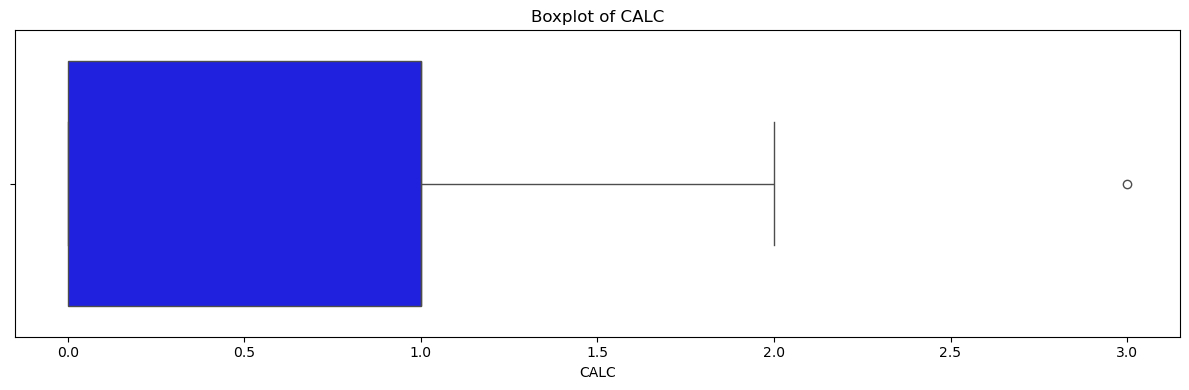

KeyError: 'MTRANS'

<Figure size 1200x400 with 0 Axes>

In [125]:
#REVISAR ESTE TAMBIEN TENGO DUDAS POR EL MTRANS, CREO QUE AL VOLVERLO DUMMIES LA CAGUE

#Boxplot
for i in integ_col:
    plt.figure(figsize=(12, 4))
    
    # Histogram
    sns.boxplot(x=df[i].dropna(), color='blue')
    
    plt.title(f'Boxplot of {i}') 
    plt.xlabel(i)
    plt.tight_layout()
    plt.show()

<Axes: >

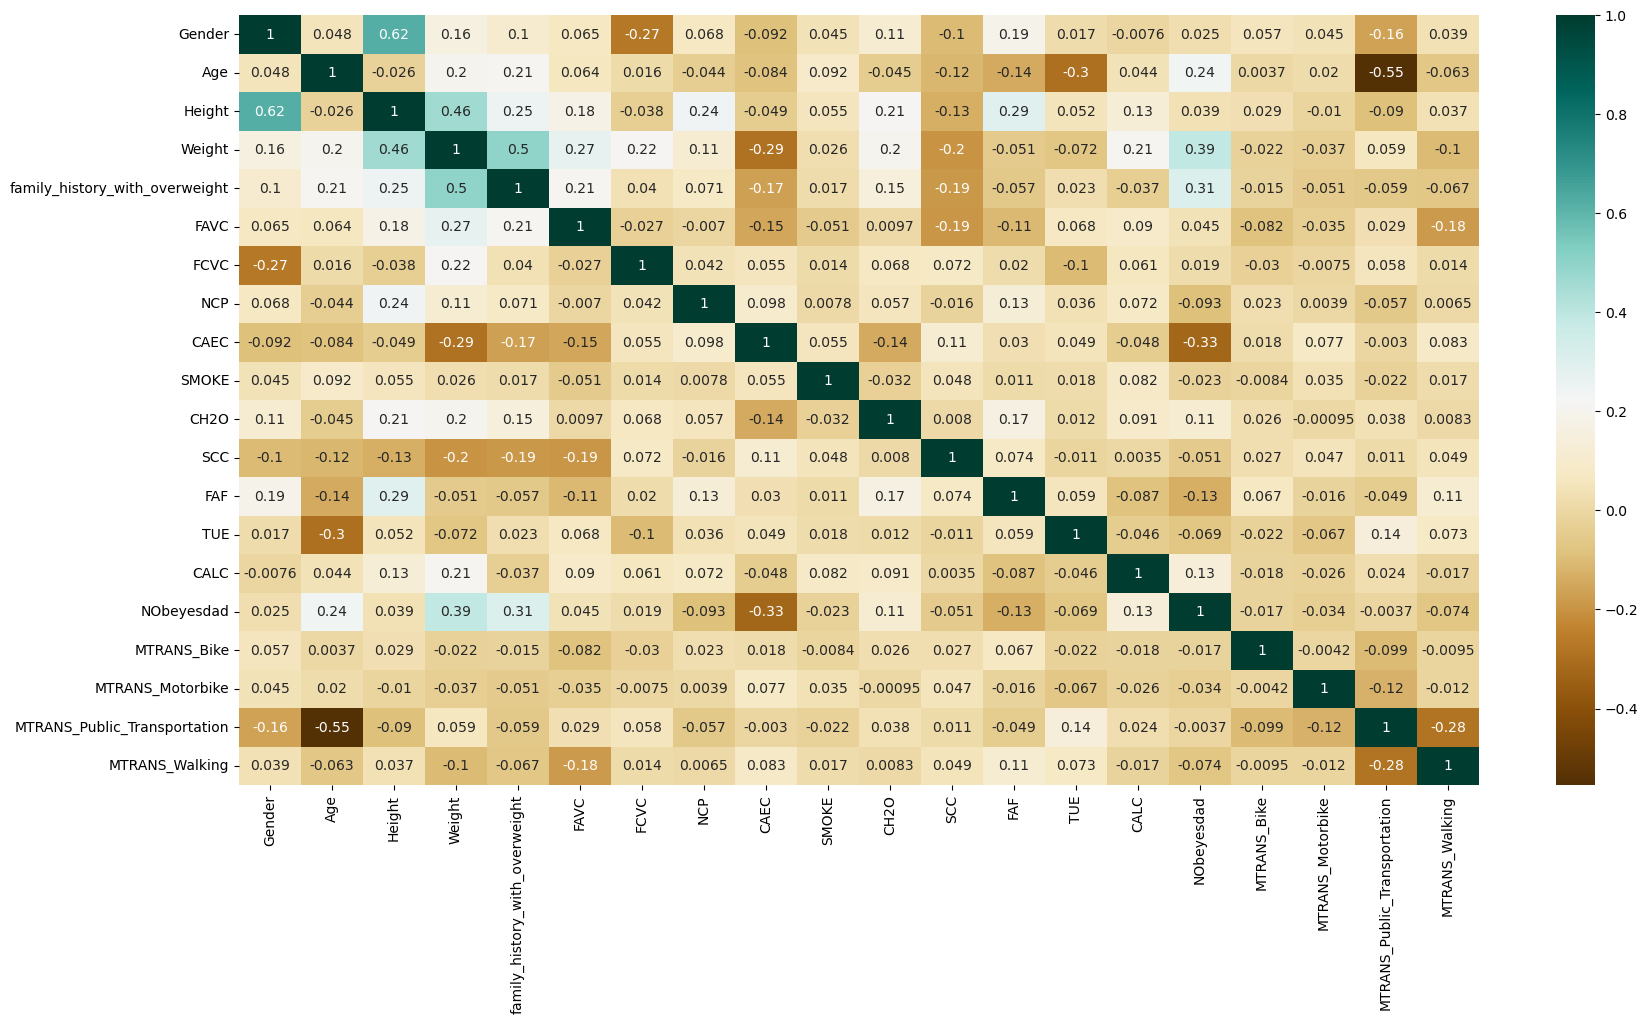

In [60]:
#Heatmap
df['NObeyesdad'] = df['NObeyesdad'].apply(pd.to_numeric, errors="coerce")

plt.figure(figsize=(20,10))
c= df.corr()
sns.heatmap(c,cmap="BrBG",annot=True)

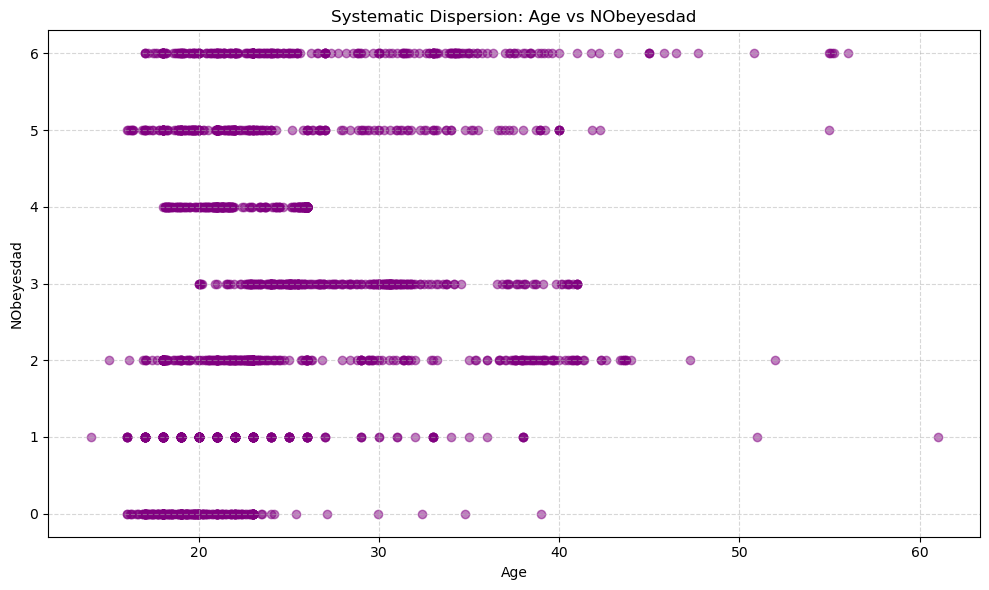

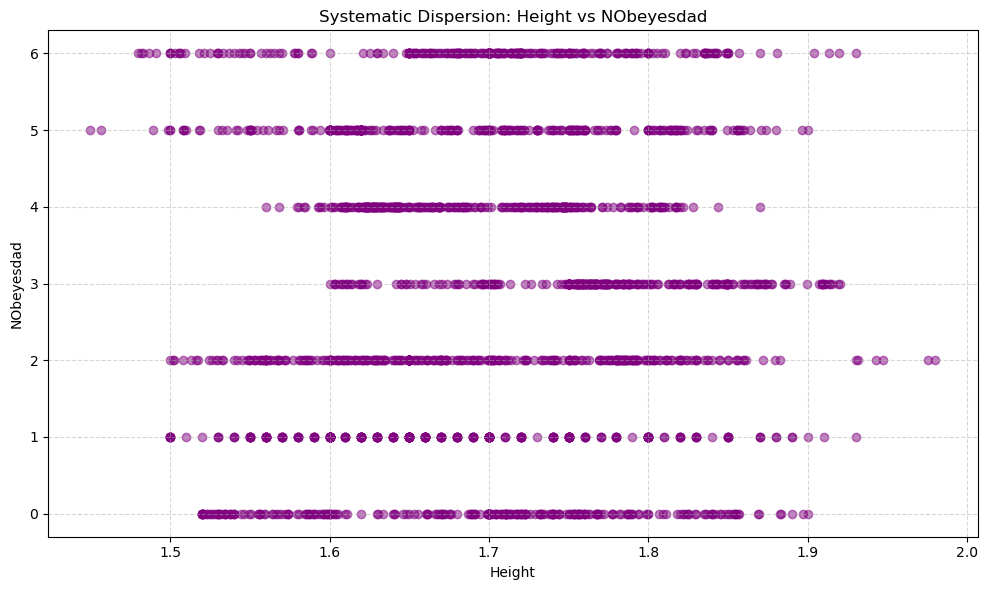

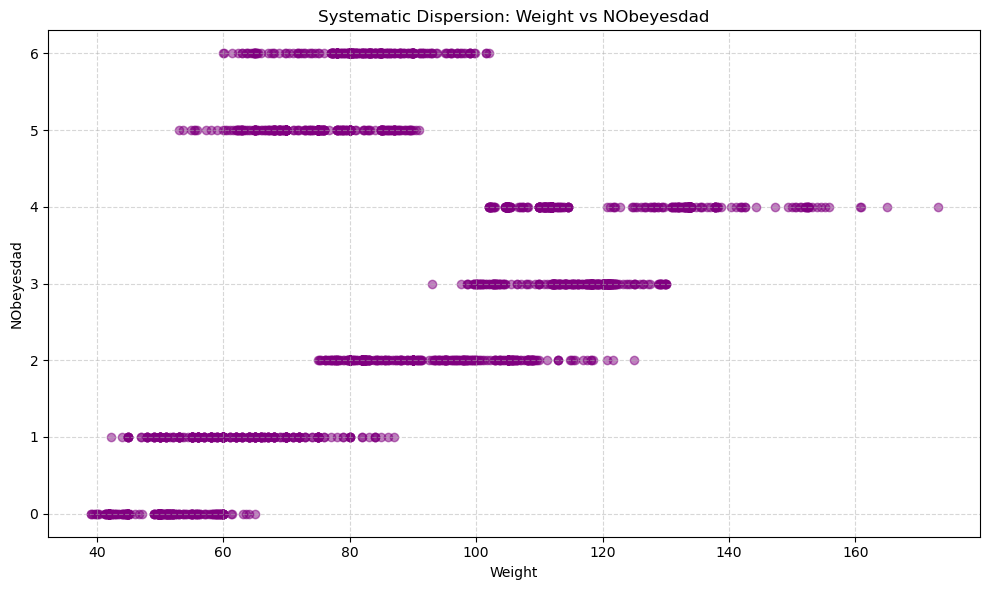

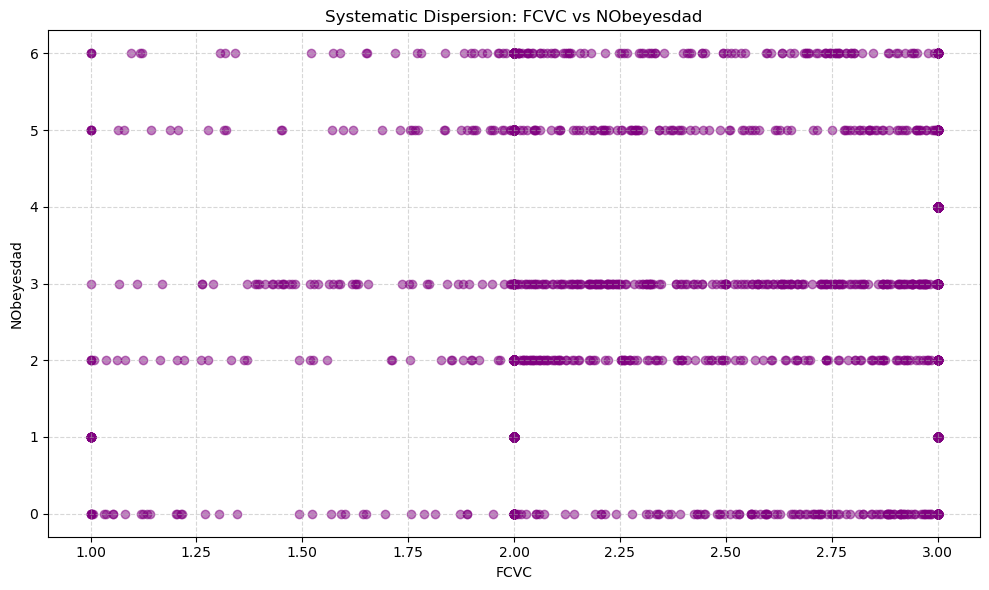

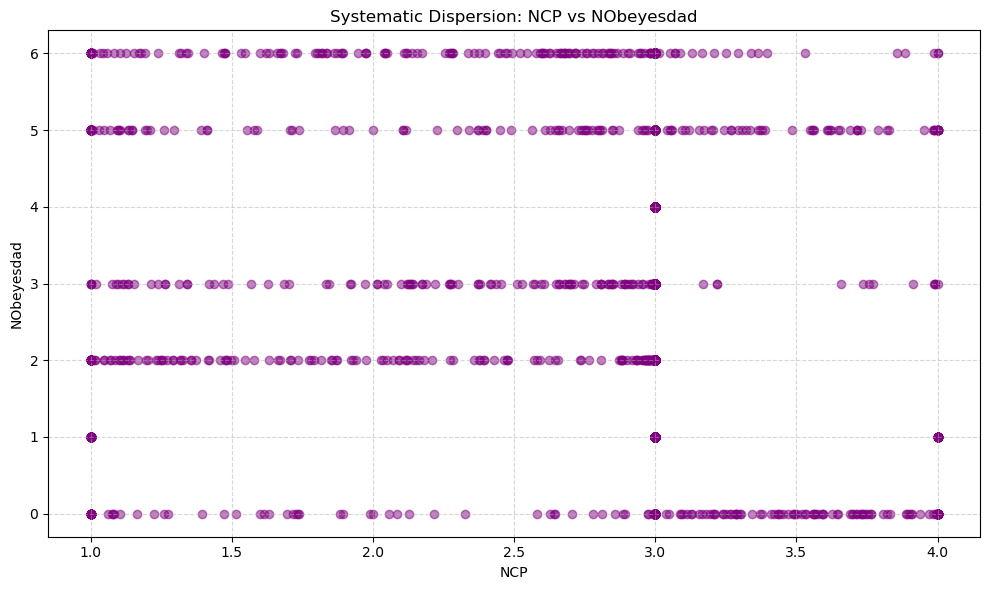

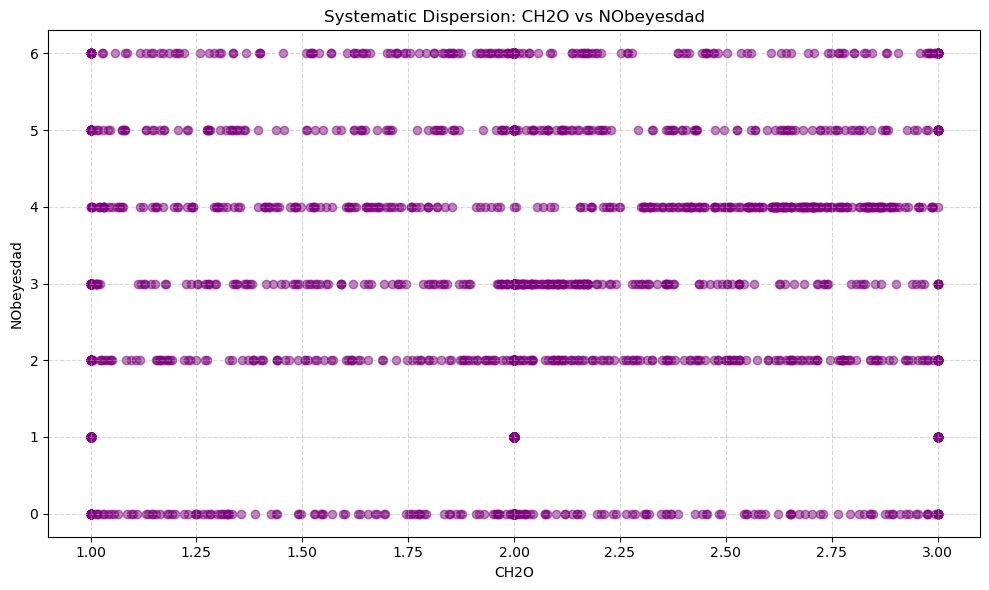

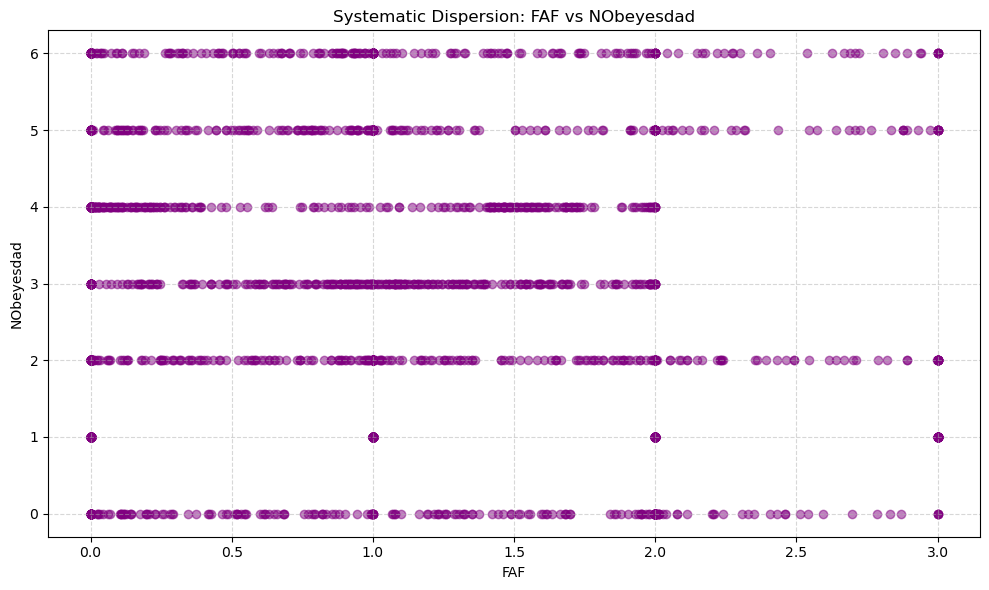

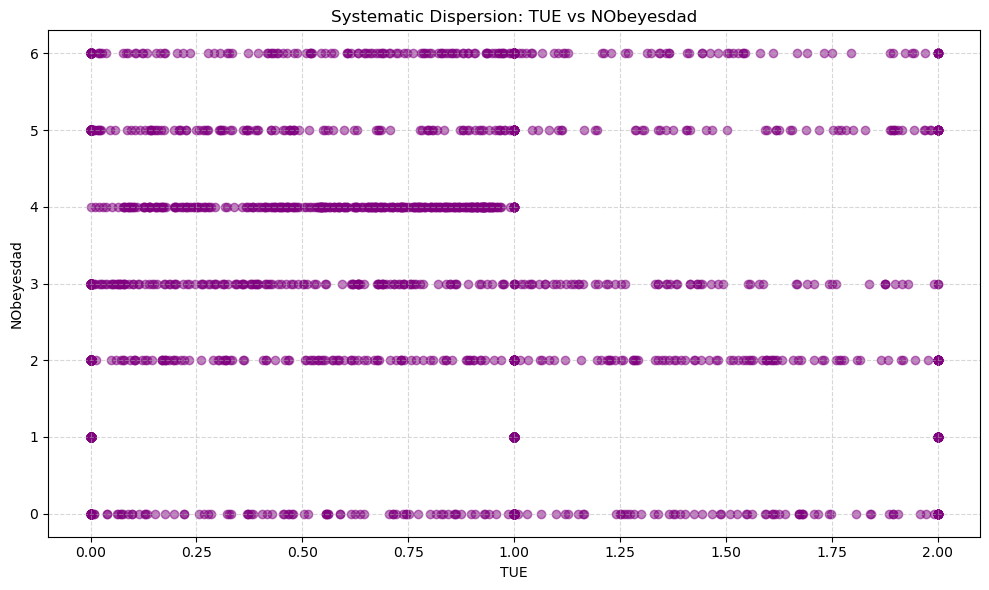

In [62]:
# Discrete and continuous columns
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Feature to use to compare graphically and delete so as not to compare the same variable
Target_variable = "NObeyesdad"
if Target_variable in num_cols:
    num_cols.remove(Target_variable)

# Numeric variable
for col in num_cols:
    fig, ax = plt.subplots(figsize=(10, 6))

    # Use alpha to different points
    ax.scatter(df[col], df[Target_variable], alpha=0.5, color="purple")
    ax.set_title(f"Systematic Dispersion: {col} vs {Target_variable}")
    ax.set_xlabel(col)
    ax.set_ylabel(Target_variable)
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

In [127]:
#REVISAR NO SE PQ AHORA ME DA ERROR, ES POR MTRANS??
columns_zscore = ['Age', 'Height', 'Weight', 'FCVC', 'CH2O', 'Gender', 'family_history_with_overweight', 'FAVC', 'NCP', 'CAEC', 'SMOKE',
                  'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS']

scaler = StandardScaler()
df[columns_zscore] = scaler.fit_transform(df[columns_zscore])

for col in columns_zscore:
    plt.figure
    sns.histplot(df[col], kde=True, color="steelblue")
    plt.title(f"Z-score: {col}")
    plt.xlabel(f"{col} (Standarization units)")
    plt.ylabel("Frequency")
    plt.show()

KeyError: "['MTRANS'] not in index"

# Supervised Learning

In [75]:
# Store the column 'NObeyesdad' in 'label'
label = df[['NObeyesdad']]

# Display first 5 records
label.head()

,NObeyesdad
0,1
1,1
2,1
3,5
4,6


In [77]:
# Drop the label column (Last)
df_1 = df.drop(['NObeyesdad'], axis = 1)

# axis = 1 means along columnwise

In [79]:
# Display last 5 records
df_1.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking
0,0,21.0,1.62,64.0,1,0,2.0,3.0,1,0,2.0,0,0.0,1.0,0,False,False,True,False
1,0,21.0,1.52,56.0,1,0,3.0,3.0,1,1,3.0,1,3.0,0.0,1,False,False,True,False
2,1,23.0,1.80,77.0,1,0,2.0,3.0,1,0,2.0,0,2.0,1.0,2,False,False,True,False
3,1,27.0,1.80,87.0,0,0,3.0,3.0,1,0,2.0,0,2.0,0.0,2,False,False,False,True
4,1,22.0,1.78,89.8,0,0,2.0,1.0,1,0,2.0,0,0.0,0.0,1,False,False,True,False


In [81]:
# Store the values as X and y before applying the ML model
# For a machine learning model, we need to split the data into independent and dependent variables

X = df_1           # Features (independent variables) from the ObesityDataSet

y = label            # Target variable (NObeyesdad) for the prediction

# Regarding the dataset

In [83]:
# Display the label variables of binary types
y.value_counts()

NObeyesdad
2             351
4             324
3             297
5             290
6             290
1             287
0             272
Name: count, dtype: int64

In [85]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42) # 80% training and 20% test
# Controls the shuffling applied to the data before applying the split.

In [87]:
# Display the rows and columns (dimenions) of an unsplitted dataset
print('Total number of rows and columns for the complete dataset: ', X.shape, y.shape)

# Display the rows and columns (dimenions) of the splitted dataset
print('Number of rows and columns after splitting dataset: ', X_train.shape, X_test.shape, y_train.shape, y_test.shape )

Total number of rows and columns for the complete dataset:  (2111, 19) (2111, 1)
Number of rows and columns after splitting dataset:  (1688, 19) (423, 19) (1688, 1) (423, 1)


# SVM

In [90]:
# Create a classifier
cls_svm = svm.SVC(kernel = "linear")    # Press shift + tab key simultaneoulsy to get the help for the function or method SVC

# Train the model
cls_svm.fit(X_train, y_train)

# Predict the response
y_pred = cls_svm.predict(X_test)

In [92]:
# accuracy
print("accuracy:", metrics.accuracy_score(y_test, y_pred))

# precision, recall and f1 with average = wiegth 
precision = metrics.precision_score(y_test, y_pred, average="weighted")
recall = metrics.recall_score(y_test, y_pred, average="weighted")
f1 = metrics.f1_score(y_test, y_pred, average="weighted")

# Classification report
print("precision:", precision)
print("recall:", recall)
print("f1:", f1)
print(metrics.classification_report(y_test, y_pred))

accuracy: 0.8888888888888888
precision: 0.8922703596668546
recall: 0.8888888888888888
f1: 0.8851626680050401
              precision    recall  f1-score   support

           0       0.82      1.00      0.90        56
           1       0.91      0.63      0.74        62
           2       0.92      0.94      0.93        78
           3       0.94      1.00      0.97        58
           4       1.00      1.00      1.00        63
           5       0.77      0.86      0.81        56
           6       0.85      0.78      0.81        50

    accuracy                           0.89       423
   macro avg       0.89      0.89      0.88       423
weighted avg       0.89      0.89      0.89       423



In [94]:
# Display the unique classes present in y_test and their counts
unique_classes, class_counts = np.unique(y_test, return_counts=True)

for cls, count in zip(unique_classes, class_counts):
    print(f"Class {cls}: Count = {count}")

Class 0: Count = 56
Class 1: Count = 62
Class 2: Count = 78
Class 3: Count = 58
Class 4: Count = 63
Class 5: Count = 56
Class 6: Count = 50


In [96]:
# Display the unique classes present in y_test and their counts
unique_classes, class_counts = np.unique(y_pred, return_counts=True)

for cls, count in zip(unique_classes, class_counts):
    print(f"Class {cls}: Count = {count}")

Class 0: Count = 68
Class 1: Count = 43
Class 2: Count = 79
Class 3: Count = 62
Class 4: Count = 63
Class 5: Count = 62
Class 6: Count = 46


<Axes: >

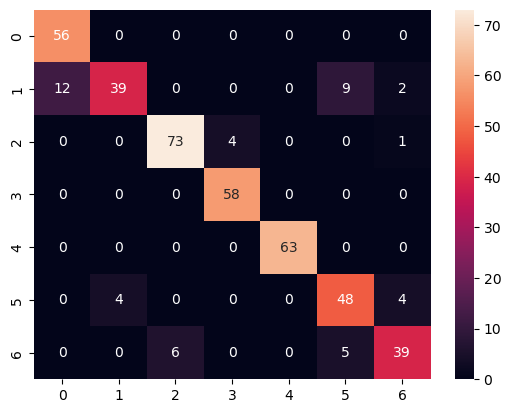

In [98]:
# Call a method predict by using an object classifier 'cls_svm'
y_predict = cls_svm.predict(X_test)

# Calculate cm by calling a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Call a method heatmap() to plot confusion matrix
sns.heatmap(cm, annot = True)

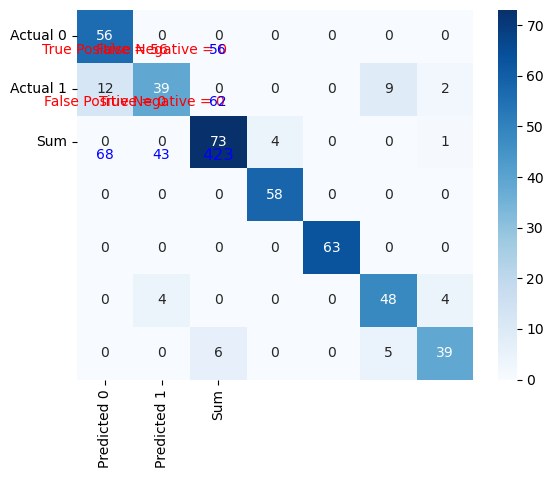

In [100]:
# Call a method predict by using an object classifier 'cls_svm'
y_predict = cls_svm.predict(X_test)

# Calculate cm by calling a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Define labels for the confusion matrix
labels = ['True Positive', 'False Negative', 'False Positive', 'True Negative']

# Create a heatmap with annotations and sum of rows/columns
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted 0', 'Predicted 1', 'Sum'], yticklabels=['Actual 0', 'Actual 1', 'Sum'])

# Add labels for TP, FP, TN, FN
for i in range(len(labels)):
    plt.text(i % 2 + 0.5, int(i / 2) + 0.75, str(labels[i]) + " = " + str(cm.flatten()[i]), color='red', fontsize=10, ha='center', va='center')

# Add sum of rows and columns
for i in range(2):
    plt.text(2.5, i + 0.75, str(cm.sum(axis=1)[i]), color='blue', fontsize=10, ha='center', va='center')
    plt.text(i + 0.5, 2.75, str(cm.sum(axis=0)[i]), color='blue', fontsize=10, ha='center', va='center')

# Add overall sum
plt.text(2.5, 2.75, str(cm.sum()), color='blue', fontsize=12, ha='center', va='center')

# Show the plot
plt.show()

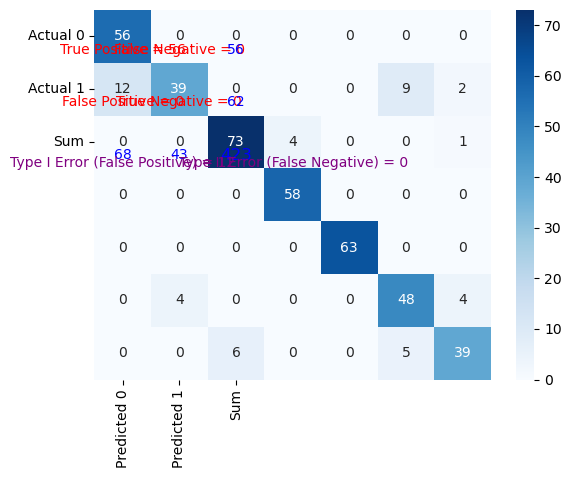

In [102]:
# Call a method predict by using an object classifier 'cls_svm'
y_predict = cls_svm.predict(X_test)

# Calculate cm by calling a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Define labels for the confusion matrix
labels = ['True Positive', 'False Negative', 'False Positive', 'True Negative']

# Create a heatmap with annotations and sum of rows/columns
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted 0', 'Predicted 1', 'Sum'], yticklabels=['Actual 0', 'Actual 1', 'Sum'])

# Add labels for TP, FP, TN, FN
for i in range(len(labels)):
    plt.text(i % 2 + 0.5, int(i / 2) + 0.75, str(labels[i]) + " = " + str(cm.flatten()[i]), color='red', fontsize=10, ha='center', va='center')

# Add sum of rows and columns
for i in range(2):
    plt.text(2.5, i + 0.75, str(cm.sum(axis=1)[i]), color='blue', fontsize=10, ha='center', va='center')
    plt.text(i + 0.5, 2.75, str(cm.sum(axis=0)[i]), color='blue', fontsize=10, ha='center', va='center')

# Add overall sum
plt.text(2.5, 2.75, str(cm.sum()), color='blue', fontsize=12, ha='center', va='center')

# Add Type I and Type II labels
plt.text(0.5, 2.9, f"Type I Error (False Positive) = {cm[1, 0]}", color='purple', fontsize=10, ha='center', va='center')
plt.text(1.5, 2.9, f"Type II Error (False Negative) = {cm[0, 1]}", color='purple', fontsize=10, ha='left', va='center')

# Show the plot
plt.show()

# KNN Model

In [105]:
# Create KNN Classifier
kNN = KNeighborsClassifier(n_neighbors = 3)

# Train the model using the training sets
kNN.fit(X_train, y_train)

# Predict the response for test dataset
y_pred = kNN.predict(X_test)

In [107]:
# Model Accuracy, how often is the classifier correct?
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )

Accuracy: 0.90


## Matrix Confusion

<Axes: >

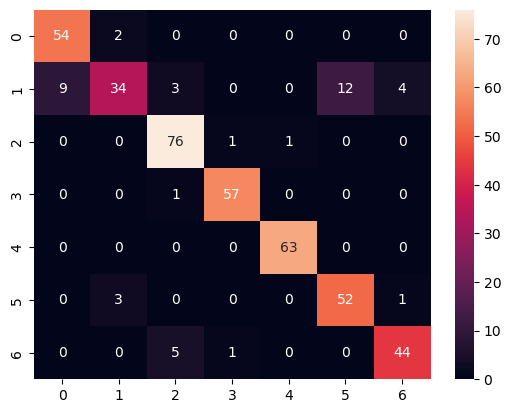

In [110]:
# Call a method predict by using an object classifier 'cls_svm'
y_predict = kNN.predict(X_test)

# Calculate cm by calling a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Call a method heatmap() to plot confusion matrix
sns.heatmap(cm, annot = True)

## Classification Report

In [113]:
# Display the classification report
print(classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           0       0.86      0.96      0.91        56
           1       0.87      0.55      0.67        62
           2       0.89      0.97      0.93        78
           3       0.97      0.98      0.97        58
           4       0.98      1.00      0.99        63
           5       0.81      0.93      0.87        56
           6       0.90      0.88      0.89        50

    accuracy                           0.90       423
   macro avg       0.90      0.90      0.89       423
weighted avg       0.90      0.90      0.89       423



## KNeighbors Classifier

In [116]:
neighbors = np.arange(1, 11)                  # number of neighbors
train_accuracy = np.zeros(len(neighbors))     # Declare and initialise the matrix
test_accuracy = np.zeros(len(neighbors))      # Declare and initialise the matrix

In [118]:
for i, k in enumerate(neighbors):                          # for loop that checks the model for neighbor values 1, 2, 3, ..., 10
    kNN = KNeighborsClassifier(n_neighbors = k)            # Initialise an object knn using KNeighborsClassifier method

    # Fit the model
    kNN.fit(X_train, y_train)                              # Call fit method to implement the ML KNeighborsClassifier model

    # Compute accuracy on the training set
    train_accuracy[i] = kNN.score(X_train, y_train)        # Save the score value in the train_accuracy array

    # Compute accuracy on the test set
    test_accuracy[i] = kNN.score(X_test, y_test)           # Save the score value in the train_accuracy array

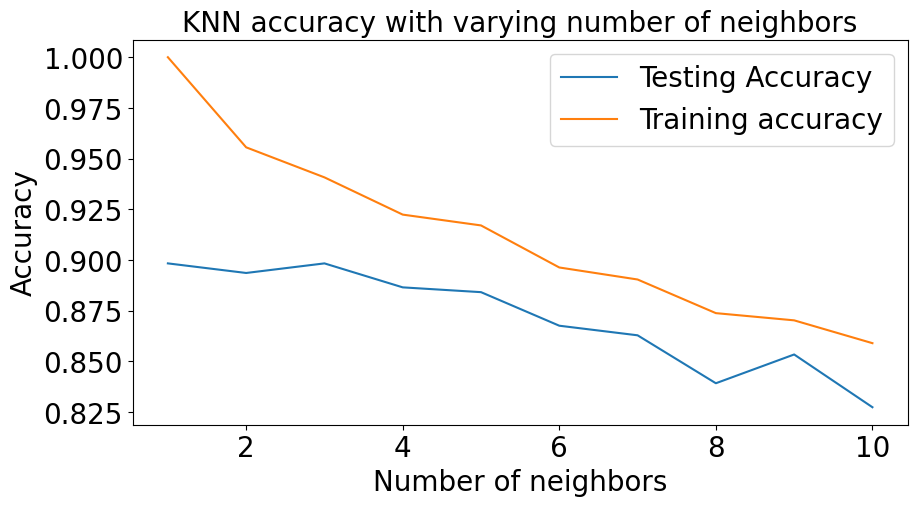

In [120]:
plt.figure(figsize = (10, 5))
plt.title('KNN accuracy with varying number of neighbors', fontsize = 20)
plt.plot(neighbors, test_accuracy, label = 'Testing Accuracy')
plt.plot(neighbors, train_accuracy, label = 'Training accuracy')
plt.legend(prop={'size': 20})
plt.xlabel('Number of neighbors', fontsize = 20)
plt.ylabel('Accuracy', fontsize = 20)
plt.xticks(fontsize = 20)
plt.yticks(fontsize = 20)
plt.show()

## KNN Regression